In [29]:
import matplotlib.pyplot as plt
import numpy as np

In [49]:
## Parameters 
N = 256 ## Grid size  
Du, Dv, dt = 0.2, 0.1, 1.0
F, k = 0.045, 0.04 ## Feed rate and kill rate

## Seed for random number generator
rng = np.random.default_rng(0)



## Concentration of U and V in each cell 
U = np.ones((N, N))  ## Initially U is one everywhere 
V = np.zeros((N, N))  ## and V is zero everywhere 

## Except, in the center of the grid, where (U, V) = (0.5, 0.25) 
center_u, center_v = 0.5, 0.25
## let c be the center point of the grid
c = N // 2 
## Then we slice the center grid 
center_grid = (slice(c - 10, c + 10), slice(c - 10, c + 10))   # 20x20 block
U *= rng.uniform(0.95, 1.05, size=(N, N))
V *= rng.uniform(0.95, 1.05, size=(N, N))


## This center grid will have (U,V) = (0.5, 0.25)
V[center_grid] = rng.uniform(center_v, center_u, size = (20, 20)) 
U[center_grid] = 1 - 2 * V[center_grid]


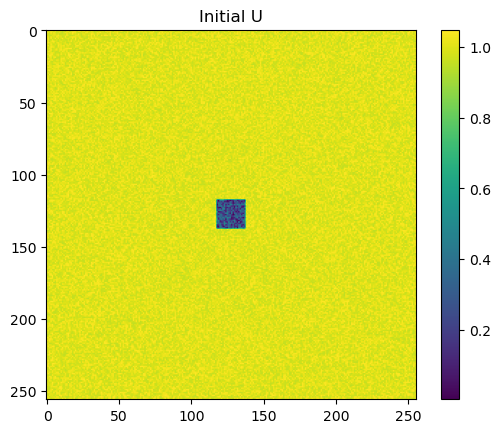

In [47]:
# This code diplays the grid we set in the previous code chunk 
plt.imshow(U, cmap="viridis")
plt.colorbar()
plt.title("Initial U")
plt.show()

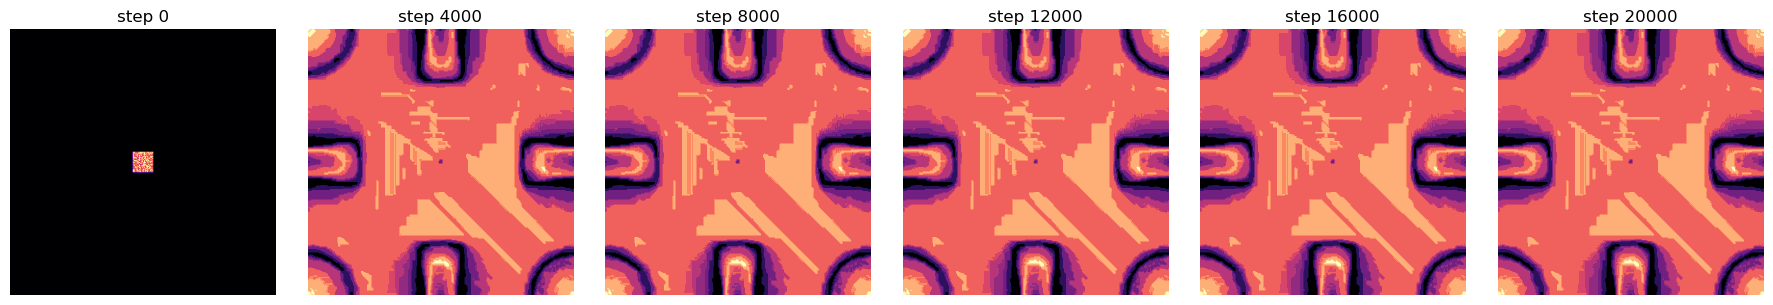

V range: 0.42303845686699704 0.4230384568669977


In [50]:

## Laplacian function that calculates the average concentration of a cell's neigbours 
            
import numpy as np
from scipy.ndimage import convolve #

# 5 point stencil for the laplacian
stencil5 = np.array([[0,  1, 0],
                    [1, -4, 1],
                    [0,  1, 0]])


def laplacian(Z):
    return convolve(Z, stencil5, mode='wrap')  # laplacian 
## Forward Euler Integration
def step(U, V):
    
    lapU = laplacian(U)
    lapV = laplacian(V)
    uvv = U * V * V                      # the reaction term UV^2, computed once

    U_new = U + dt * (Du * lapU - uvv + F * (1 - U))
    V_new = V + dt * (Dv * lapV + uvv - (F + k) * V)
    return U_new, V_new


# Simulate 20000 times, with a snapshot of the system for every 4000 steps 
n_steps = 20000
snap_every = 4000 # Snapshot interval
snapshots = []

for i in range(n_steps + 1):
    if i % snap_every == 0: ## Is this a multiple of 4000?
        snapshots.append((i, V.copy())) ## Append this figure to the list of snapshots
    U, V = step(U, V) ## Move to the next step in the integration


 
## Code for making figures 
fig, axes = plt.subplots(1, len(snapshots), figsize=(3 * len(snapshots), 3))
for ax, (i, snap) in zip(axes, snapshots):
    ax.imshow(snap, cmap="magma")
    ax.set_title(f"step {i}")
    ax.axis("off")
plt.tight_layout()
plt.show()

print("V range:", V.min(), V.max())

In [ ]:
## Setup the initial values for the Gray Scott Model
def setup(feed_rate, kill_rate):
    D_u, D_v = 0.1, 0.1 # Diffusion rates for U and V   
    initial_U, initial_V = 1 / 2, 1 / 4
    n_sims = 1000
    
    

## Euler Integration
def step(U, V, F, k):
    lapU = laplacian(U)
    lapV = laplacian(V)
    uvv = U * V * V
    U_new = U + dt * (Du * lapU - uvv + F * (1 - U))
    V_new = V + dt * (Dv * lapV + uvv - (F + k) * V)
    return U_new, V_new


## Code for Parameter Map
feed_rates = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]   
kill_rates = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6] 

## We simulate 6 x 6 times. 

for i in range(len(feed_rates)): 
    for j in range(len(kill_rates)):
        simulate(feed_rate, kill_rate)

        


 